# Figure 1 · The galaxy sample

**Question:** What galaxies enter this study, and what do the paired observations look like?

**Status:** v02 retains panels a, c and d and replaces the accounting chart with
matched NISP Y and JWST F115W observations. The available image package contains
~12-arcsec cutouts, not complete 3-arcmin block mosaics. Panel b is explicitly a
smaller field inside the highlighted validation block. No models are run.

The footprint includes held-out positions/counts to document the split design;
property distributions use training and validation only. Image data are from
one validation object, selected using input metadata before looking at images.


In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Works from the repository root or from paper_figures/.
here = Path.cwd()
workspace = here if (here / 'figure_utils.py').exists() else here / 'paper_figures'
if str(workspace) not in sys.path:
    sys.path.insert(0, str(workspace))
from figure_utils import (ROOT, FIGURES, DATA, COLORS, style, read_json, export,
                          panel, box, arrow, verified_sources, completed_evaluation,
                          run_inventory, sha)
%matplotlib inline
style()
VERSION = 'v02'

In [2]:
# Review controls: figure size, histogram bins, colors, export version.
FIGSIZE = (7.2, 6.0)
PROPERTY_SPLITS = ['train', 'validation']
manifest_path = DATA / 'manifest.json'
objects_path = DATA / 'objects.csv'
manifest = read_json(manifest_path)
objects = pd.read_csv(objects_path)
assert len(objects) == manifest['accepted']
assert objects.id_classic.is_unique and objects.row.is_unique
assert objects.groupby('split').size().to_dict() == manifest['split_counts']
assert manifest['accepted'] + sum(manifest['rejection_counts'].values()) == manifest['candidates']
display(pd.DataFrame({'split': list(manifest['split_counts']),
                      'galaxies': list(manifest['split_counts'].values())}))
print('Selection:', manifest['selection'])
print('Quality:', manifest['quality'])

# Cached real observations: extraction details, source identity and selection are
# recorded in the JSON. To switch to a whole-block view, supply original mosaics.
zoom_path = FIGURES / 'inputs/sample_zoom_v02.npz'
zoom_metadata_path = FIGURES / 'inputs/sample_zoom_v02.json'
zoom = read_json(zoom_metadata_path)
assert zoom['split'] == 'validation' and zoom['units'] == 'sky-subtracted MJy/sr'
assert sha(zoom_path) == zoom['npz_sha256']
selected = objects.loc[objects.row == zoom['row']].iloc[0]
assert selected.split == 'validation' and int(selected.id_classic) == zoom['object_id']
with np.load(zoom_path, allow_pickle=False) as saved:
    images = dict(saved)
assert images['nisp'].shape == images['nisp_valid'].shape == (41, 41)
assert images['jwst'].shape == images['jwst_valid'].shape == (205, 205)
print('Example selection:', zoom['selection'])
print('Validation block:', zoom['spatial_block'], '; object:', zoom['object_id'])
# Shared physical-intensity stretch; tweak these display-only controls together.
DISPLAY_LOW = -.03
DISPLAY_HIGH = float(np.percentile(images['jwst'][images['jwst_valid']], 99.8))
ASINH_SOFTENING = .04  # MJy/sr; same in both bands


,split,galaxies
0,train,17816
1,test,2876
2,validation,2118


Selection: lp_type==0; ACS_F814W_MAG<25; .01<ez_z_phot<3; 4<FLUX_RADIUS<500; existing dated coverage candidates
Quality: DQ==0; finite SCI and positive finite RMS<1e7; >=95% coverage each instrument; central 5x5 NISP /25x25 HR fully valid
Example selection: Most populated validation block; brightest ACS F814W accepted galaxy within it (tie: object ID). Input metadata only.
Validation block: 4:2 ; object: 742196


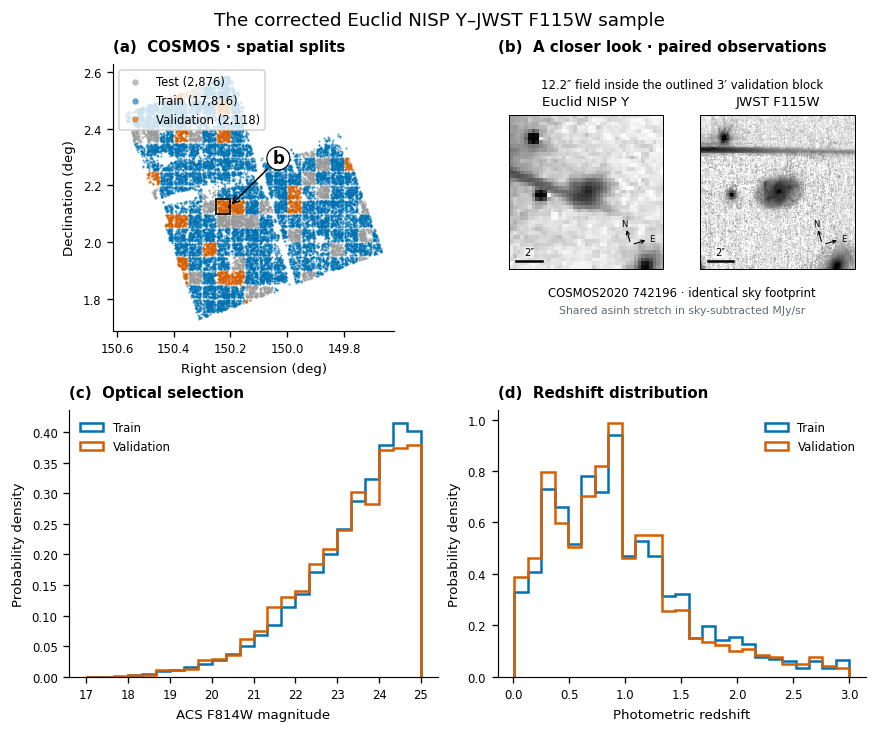

In [3]:
from matplotlib.patches import Rectangle, Polygon
from matplotlib.colors import AsinhNorm

fig, axes = plt.subplots(2, 2, figsize=FIGSIZE, layout='constrained')
ax = axes[0, 0]
for split in ['test', 'train', 'validation']:
    group = objects[objects.split == split]
    ax.scatter(group.ra, group.dec, s=1.6, alpha=.65, color=COLORS[split],
               linewidths=0, rasterized=True,
               label=f"{split.capitalize()} ({len(group):,})")
ax.set(xlabel='Right ascension (deg)', ylabel='Declination (deg)')
ax.invert_xaxis()
ax.set_aspect(1 / np.cos(np.deg2rad(objects.dec.mean())))
ax.legend(loc='upper left', markerscale=3, frameon=True, facecolor='white')
panel(ax, 'a', 'COSMOS · spatial splits')
ra0, ra1 = zoom['block_ra_edges_deg']; dec0, dec1 = zoom['block_dec_edges_deg']
ax.add_patch(Rectangle((ra0, dec0), ra1-ra0, dec1-dec0,
    fill=False, edgecolor='#202020', linewidth=1.2, zorder=5))
ax.add_patch(Polygon(zoom['corners_ra_dec_deg'], closed=True,
    fill=False, edgecolor='black', linewidth=.7, zorder=6))
ax.annotate('b', xy=zoom['center_ra_dec_deg'], xytext=(26, 26),
    textcoords='offset points', color='black', fontsize=10, fontweight='bold',
    bbox=dict(boxstyle='circle,pad=.15', fc='white', ec='black', lw=.7),
    arrowprops=dict(arrowstyle='->', color='black', lw=.9), zorder=7)

# Two observations of the same footprint; preserve native NISP sampling.
ax = axes[0, 1]
ax.set_axis_off()
panel(ax, 'b', 'A closer look · paired observations')
field = 41 * zoom['nisp_pixel_scale_arcsec']
extent = [-field/2, field/2, -field/2, field/2]
norm = AsinhNorm(linear_width=ASINH_SOFTENING, vmin=DISPLAY_LOW, vmax=DISPLAY_HIGH)
cmap = plt.get_cmap('gray_r').copy(); cmap.set_bad('#B0B0B0')
for left, name, title in [(0.0, 'nisp', 'Euclid NISP Y'), (.52, 'jwst', 'JWST F115W')]:
    view = ax.inset_axes([left, .23, .48, .58])
    image = np.ma.array(images[name], mask=~images[name+'_valid'])
    view.imshow(image, origin='lower', extent=extent, interpolation='nearest', cmap=cmap, norm=norm)
    view.set_title(title, fontsize=8, pad=6)
    view.set_xticks([]); view.set_yticks([])
    for spine in view.spines.values(): spine.set_visible(True); spine.set_linewidth(.6)
    view.plot([extent[0]+.6, extent[0]+2.6], [extent[2]+.7]*2, color='black', lw=1.5)
    view.text(extent[0]+1.6, extent[2]+1.1, '2″', ha='center', fontsize=6,
              bbox=dict(fc='white', ec='none', alpha=.65, pad=.1))
    # WCS-derived compass; orientation is native NISP in both panels.
    origin = np.array([.79, .16])
    for direction, vector in zoom['compass_native_pixel_vectors'].items():
        vector = np.asarray(vector); end = origin + .12*vector/np.linalg.norm(vector)
        view.annotate('', xy=end, xytext=origin, xycoords='axes fraction',
                       arrowprops=dict(arrowstyle='->', color='black', lw=.65, mutation_scale=5))
        view.text(*(origin+1.2*(end-origin)), direction, transform=view.transAxes,
                  ha='center', va='center', fontsize=5)
ax.text(.5, .91, f'{field:.1f}″ field inside the outlined 3′ validation block',
        transform=ax.transAxes, ha='center', fontsize=7)
ax.text(.5, .13, f'COSMOS2020 {zoom["object_id"]} · identical sky footprint',
        transform=ax.transAxes, ha='center', fontsize=7)
ax.text(.5, .065, 'Shared asinh stretch in sky-subtracted MJy/sr',
        transform=ax.transAxes, ha='center', fontsize=6.5, color='#626A73')

population = objects[objects.split.isin(PROPERTY_SPLITS)]
mag_bins = np.linspace(np.floor(population.ACS_F814W_MAG.min()), 25, 25)
z_bins = np.linspace(.01, 3, 26)
for ax, column, bins, xlabel, letter, title in [
    (axes[1, 0], 'ACS_F814W_MAG', mag_bins, 'ACS F814W magnitude', 'c', 'Optical selection'),
    (axes[1, 1], 'ez_z_phot', z_bins, 'Photometric redshift', 'd', 'Redshift distribution')]:
    for split in PROPERTY_SPLITS:
        data = objects.loc[objects.split == split, column].dropna()
        ax.hist(data, bins=bins, density=True, histtype='step', linewidth=1.5,
                color=COLORS[split], label=split.capitalize())
    ax.set(xlabel=xlabel, ylabel='Probability density')
    ax.legend(frameon=False)
    panel(ax, letter, title)
fig.suptitle('The corrected Euclid NISP Y–JWST F115W sample', fontsize=11)
plt.show()


In [4]:
paths = export(fig, f'fig01_sample_{VERSION}', '01_sample.ipynb',
               [manifest_path, objects_path, zoom_path, zoom_metadata_path],
               dict(figsize=FIGSIZE, property_splits=PROPERTY_SPLITS,
                    sample_count=len(objects), split_counts=manifest['split_counts'],
                    zoom_object_id=zoom['object_id'], zoom_block=zoom['spatial_block'],
                    zoom_field_arcsec=field, display_low=DISPLAY_LOW,
                    display_high=DISPLAY_HIGH, asinh_softening=ASINH_SOFTENING,
                    test_access='positions and counts only; images from validation only'),
               status='sample draft v02: paired validation cutout within highlighted block')


Exported: fig01_sample_v02.pdf, fig01_sample_v02.svg, fig01_sample_v02.png


## Working caption

The matched COSMOS sample. (a) Accepted galaxies are divided into spatial
training, validation and reserved-test regions using 3-arcmin blocks and
10-arcsec boundary buffers. The outlined validation block contains the
small field shown in (b): aligned Euclid NISP Y and JWST F115W observations
of COSMOS2020 742196, covering 12.2 arcsec with 2-arcsec scale bars. The small
polygon marks the actual cutout footprint; it is not the entire block.
Both images use the same physical-intensity asinh stretch; compass arrows
show north and east. NISP retains its native sampling; JWST was WCS-aligned
to the five-times-finer training target grid. (c,d) Optical-magnitude and
photometric-redshift distributions of training and validation galaxies.
This optically selected sample is not NISP-complete.

## Review together

- The complete 3-arcmin mosaic remains an option once original images are available.
- This example was selected as the brightest ACS F814W object in the most
  populated validation block; it is illustrative, not a representative galaxy.
- Exact sample cuts and rejection accounting can move to a table.
- Catalog `FLUX_RADIUS` is not labeled in arcseconds without verifying its units.
- JWST coverage is a finite/nonzero SCI proxy; no JWST RMS/DQ was supplied.
- v01 exports and the original notebook in `revisions/` preserve the previous layout.
